# Sentiment analysis

Run this notebook with your local Python environment, from the repository root or this notebook folder. The dataset is `data/train.csv`; Google Drive is not required.

Install the project dependencies first. If needed, install language detection in the active kernel with `%pip install langdetect`. The spaCy model can be installed with `%pip install https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl`. NLTK downloads its VADER lexicon on the first run (Internet required).

Run the cells in order. Preprocessing and training use a 3% sample of the dataset and may take several minutes locally. The trained spaCy model is saved to `classifier_spacy/` beside this notebook.

# Twitter dataset

## Loading the data

In [1]:
# !pip install spacy --upgrade

In [2]:
# !python -m spacy download en_core_web_sm

In [3]:
import spacy
import en_core_web_sm
import pandas as pd
import seaborn as sns
import numpy as np
import re
import random
from pathlib import Path

In [4]:
# Support kernels started at the repository root or in this notebook's folder.
notebook_dir = Path.cwd()
course_dir = notebook_dir / '65.The-Ultimate-Beginners-Guide-to-Natural-Language-Processing'
if course_dir.is_dir():
  notebook_dir = course_dir
data_file = notebook_dir / 'data' / 'train.csv'
model_dir = notebook_dir / 'classifier_spacy'
if not data_file.is_file():
  raise FileNotFoundError(
    f'Dataset not found: {data_file}. Start the kernel at the repository root '
    'or in this notebook folder and place train.csv in its data/ directory.'
  )


In [5]:
train_data = pd.read_csv(data_file, header=None,
                         names=['sentiment', 'id', 'date', 'query', 'user', 'text'], encoding='latin1')

In [6]:
train_data

,sentiment,id,date,query,user,text
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all...."
...,...,...,...,...,...,...
1599995,4,2193601966,Tue Jun 16 08:40:49 PDT 2009,NO_QUERY,AmandaMarie1028,Just woke up. Having no school is the best fee...
1599996,4,2193601969,Tue Jun 16 08:40:49 PDT 2009,NO_QUERY,TheWDBoards,TheWDB.com - Very cool to hear old Walt interv...
1599997,4,2193601991,Tue Jun 16 08:40:49 PDT 2009,NO_QUERY,bpbabe,Are you ready for your MoJo Makeover? Ask me f...
1599998,4,2193602064,Tue Jun 16 08:40:49 PDT 2009,NO_QUERY,tinydiamondz,Happy 38th Birthday to my boo of alll time!!! ...


In [7]:
train_data['sentiment'].unique()

array([0, 4])

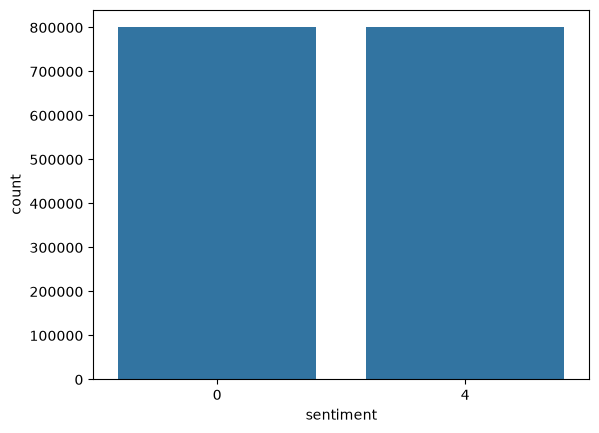

In [8]:
sns.countplot(data=train_data, x='sentiment');

In [9]:
np.unique(train_data['sentiment'], return_counts=True)

(array([0, 4]), array([800000, 800000]))

In [10]:
train_data = train_data.drop(['id', 'date', 'query', 'user'], axis=1)
train_data

,sentiment,text
0,0,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,is upset that he can't update his Facebook by ...
2,0,@Kenichan I dived many times for the ball. Man...
3,0,my whole body feels itchy and like its on fire
4,0,"@nationwideclass no, it's not behaving at all...."
...,...,...
1599995,4,Just woke up. Having no school is the best fee...
1599996,4,TheWDB.com - Very cool to hear old Walt interv...
1599997,4,Are you ready for your MoJo Makeover? Ask me f...
1599998,4,Happy 38th Birthday to my boo of alll time!!! ...


## Train and test data

In [11]:
X = train_data['text'].to_numpy()
X

array(["@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer.  You shoulda got David Carr of Third Day to do it. ;D",
       "is upset that he can't update his Facebook by texting it... and might cry as a result  School today also. Blah!",
       '@Kenichan I dived many times for the ball. Managed to save 50%  The rest go out of bounds',
       ..., 'Are you ready for your MoJo Makeover? Ask me for details ',
       'Happy 38th Birthday to my boo of alll time!!! Tupac Amaru Shakur ',
       'happy #charitytuesday @theNSPCC @SparksCharity @SpeakingUpH4H '],
      dtype=object)

In [12]:
y = train_data['sentiment'].to_numpy()
y

array([0, 0, 0, ..., 4, 4, 4])

In [13]:
from sklearn.model_selection import train_test_split
X, _, y, _ = train_test_split(X, y, test_size = 0.97)

In [14]:
X

array(['Hw text it ',
       'Is gonna have a 14 year old on my care very soon while her dad and my ex boyfriend (her bro) is off to jail  holy crap',
       "@alizasherman That happens to me too when I visit Manhattan. I get a punch to the heart when I 'see' the missing towers...  ",
       ..., 'gonna watch some episodes of the inbetweeners ',
       'Where is everybody?! ', '@babyducks Always such poor creatures '],
      dtype=object)

In [15]:
X.shape

(48000,)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2)

In [17]:
X_train.shape, y_train.shape

((38400,), (38400,))

In [18]:
X_test.shape, y_test.shape

((9600,), (9600,))

In [19]:
np.unique(y_train, return_counts=True)

(array([0, 4]), array([19077, 19323]))

In [20]:
np.unique(y_test, return_counts=True)

(array([0, 4]), array([4762, 4838]))

# Preprocessing the data

In [21]:
nlp = spacy.load('en_core_web_sm')
nlp

In [22]:
def preprocessing(sentence):
  sentence = sentence.lower()
  sentence = re.sub(r"@[A-Za-z0-9]+", ' ', sentence)
  sentence = re.sub(r"https?://[A-Za-z0-9./]+", ' ', sentence)
  sentence = sentence.replace('.', '')
  tokens = []
  tokens = [token.text for token in nlp(sentence) if not (token.is_stop or token.like_num or token.is_punct or token.is_space or len(token) == 1)]
  tokens = ' '.join([element for element in tokens])

  return tokens

In [23]:
preprocessing("@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer.  2 You shoulda got David Carr of Third Day to do it. ;D")

'awww bummer shoulda got david carr day'

In [24]:
X_train_cleaned = [preprocessing(tweet) for tweet in X_train]

In [25]:
len(X_train_cleaned)

38400

In [26]:
for _ in range(10):
  print(X_train_cleaned[random.randint(0, len(X_train_cleaned) - 1)])

updates
gon na find way entertain flight delayed suspose atl 1:49 leavimg akron 2:30
butler hey new zealand fair broke heart ps love awwwh twas lovely thing thank
hi great weekend bonjour bon week end
eww sand tights ew sand shoes ew ew throw shoes seawater smell shite
parched hot walking home
oh yess tomorrow cent taco day gon na holler
sounds yummy luv
ughh hate mondays 10hr day work today omg looking forward
saw community closeup til come good luck drill sgt trixie360


In [27]:
X_test_cleaned = [preprocessing(tweet) for tweet in X_test]

## Word cloud

In [28]:
texts = ''
for text in X_train_cleaned:
  texts += ' ' + text

In [29]:
texts

" oh em gee dad caught smoking quit months ago suddenly started tut tut disappointed right oldest sit play character sheet games youngest year old involved definitely check yr youtube cloudy dayy watching hannah monatana quot;jake little piece heart&quot far great watching jb live chat joe started wrapping muffin man hair beautiful broke cable guitar holy shit gon na eat way lol sure work dad gets tickets stuff lot hope plan bedtime mourning fact missing 3day campfest oregon thanks matt- falling laughing cute love chairs west elm eating merckel bbc sign dropped car yesterdaybmw week repair sick use chicken noodle facebook wo nt let notifications thing know arghh awesome thank connecticut want sun squeeze nearly birthday time!i want stick good todayhad cereal breakfast soap fruit lunch eally need chocolate woke sister came escape fate jus blast woke ina good mood tho round haha note hairy shoulders wear shirt ot shavenot tank beautiful way rockstar awesome waiting comcast fingers crosse

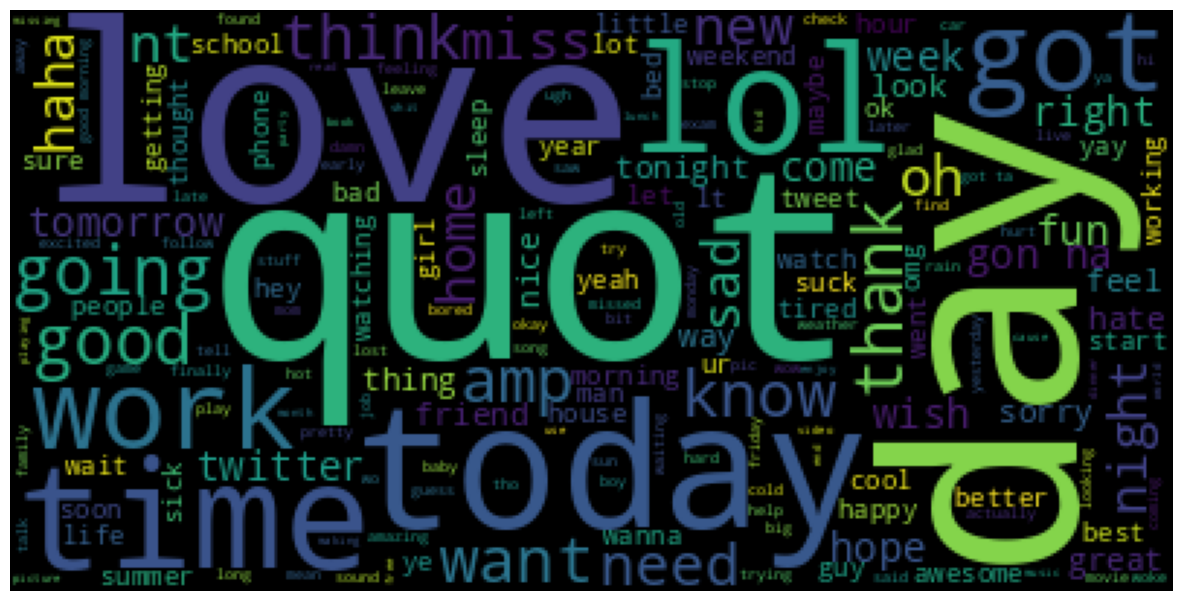

In [30]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
cloud = WordCloud()
cloud = cloud.generate(texts)
plt.figure(figsize=(15,15))
plt.imshow(cloud)
plt.axis('off');

# Detecting languages

In [31]:
# If langdetect is missing, run this in the active kernel:
# %pip install langdetect

In [32]:
from langdetect import detect, DetectorFactory, LangDetectException
DetectorFactory.seed = 0

In [33]:
detect('This is an English text')

'en'

In [34]:
detect('Este é um texto em português')

'pt'

In [35]:
detect('Este es un texto en espanõl')

'es'

In [36]:
languages = []
for text in X_test_cleaned:
  if text.strip():
    try:
      languages.append(detect(text))
    except LangDetectException:
      # Some short tweets contain no features that identify a language.
      languages.append('unknown')

In [37]:
np.unique(languages, return_counts=True)

(array(['af', 'ca', 'cs', 'cy', 'da', 'de', 'en', 'es', 'et', 'fi', 'fr',
        'hr', 'hu', 'id', 'it', 'lt', 'lv', 'nl', 'no', 'pl', 'pt', 'ro',
        'sk', 'sl', 'so', 'sq', 'sv', 'sw', 'tl', 'tr', 'vi'], dtype='<U2'),
 array([ 542,   65,   18,  163,  133,   39, 6722,   60,  125,   54,  155,
          33,    6,  103,  102,    6,    5,  168,  156,   51,   23,   77,
          26,   30,  289,   20,   83,   52,  187,   31,    9]))

# Sentiment analysis with NLTK

In [38]:
import nltk
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/ankit/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [39]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

In [40]:
nltk_classifier = SentimentIntensityAnalyzer()
nltk_classifier.polarity_scores('I love this food')

{'neg': 0.0, 'neu': 0.323, 'pos': 0.677, 'compound': 0.6369}

In [41]:
nltk_classifier.polarity_scores('I hate this food')

{'neg': 0.649, 'neu': 0.351, 'pos': 0.0, 'compound': -0.5719}

In [42]:
nltk_classifier.polarity_scores('I have this food')

{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}

In [43]:
X_train_cleaned[0]

'oh em gee dad caught smoking quit months ago suddenly started tut tut disappointed right'

In [44]:
nltk_classifier.polarity_scores(X_train_cleaned[0])

{'neg': 0.181, 'neu': 0.819, 'pos': 0.0, 'compound': -0.4767}

In [45]:
X_train_cleaned[20002]

'computer keyboard alive probably shld check sales chip help revive economy'

In [46]:
nltk_classifier.polarity_scores(X_train_cleaned[20002])

{'neg': 0.0, 'neu': 0.51, 'pos': 0.49, 'compound': 0.7717}

In [47]:
for sentence in X_test:
  print(nltk_classifier.polarity_scores(sentence), ' - ', sentence)

{'neg': 0.185, 'neu': 0.696, 'pos': 0.119, 'compound': -0.4199}  -  @nickolaswheeler I saw the red pandas in Philly! But so not the same, I will agree. Too bad you didn't see the penguins. 
{'neg': 0.379, 'neu': 0.5, 'pos': 0.121, 'compound': -0.5574}  -  @davemagill prodigy no longer 29p on Amazon. Disappointed  #Spotify instead...
{'neg': 0.0, 'neu': 0.517, 'pos': 0.483, 'compound': 0.4215}  -  twitter's a awsome website lol     
{'neg': 0.0, 'neu': 0.862, 'pos': 0.138, 'compound': 0.3404}  -  @jaredlunde when will that be - I can't be a nag if I'm in a coma in the other room! 
{'neg': 0.0, 'neu': 0.793, 'pos': 0.207, 'compound': 0.6696}  -  @bstoy Make sure you keep the Cowboy jerseys in the closet till we see how our team is this year  Be good Babs!
{'neg': 0.0, 'neu': 0.471, 'pos': 0.529, 'compound': 0.6697}  -  Presets were the fucking best 
{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}  -  hey ladies, how is everyone today 
{'neg': 0.0, 'neu': 0.629, 'pos': 0.371, 'compo

# Sentiment analysis with TF-IDF

In [48]:
X_train_cleaned[0:5]

['oh em gee dad caught smoking quit months ago suddenly started tut tut disappointed right',
 'oldest sit play character sheet games youngest year old involved',
 'definitely check yr youtube',
 'cloudy dayy',
 'watching hannah monatana quot;jake little piece heart&quot far great']

In [49]:
y_train

array([0, 4, 4, ..., 0, 0, 0])

In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train_cleaned)

In [51]:
X_train_tfidf.shape

(38400, 33602)

In [52]:
len(vectorizer.get_feature_names_out())

33602

In [53]:
def preprocessing_lemma(sentence):
  tokens = []
  tokens = [token.lemma_ for token in nlp(sentence)]
  tokens = ' '.join([element for element in tokens])
  return tokens

In [54]:
preprocessing_lemma('learn learned learning')

'learn learn learning'

In [55]:
X_train_cleaned_lemma = [preprocessing_lemma(tweet) for tweet in X_train_cleaned]

In [56]:
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train_cleaned_lemma)

In [57]:
X_train_tfidf.shape

(38400, 30232)

In [58]:
X_test_cleaned_lemma = [preprocessing_lemma(tweet) for tweet in X_test_cleaned]

In [59]:
X_test_tfidf = vectorizer.transform(X_test_cleaned_lemma)

In [60]:
X_test_tfidf.shape

(9600, 30232)

In [61]:
from sklearn.tree import DecisionTreeClassifier

In [62]:
classifier = DecisionTreeClassifier()
classifier.fit(X_train_tfidf, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [63]:
predictions = classifier.predict(X_test_tfidf)

In [64]:
predictions

array([0, 0, 4, ..., 0, 4, 0])

In [65]:
y_test

array([0, 0, 4, ..., 0, 4, 0])

In [66]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [67]:
accuracy_score(y_test, predictions)

0.6809375

In [68]:
cm = confusion_matrix(y_test, predictions)
cm

array([[3385, 1377],
       [1686, 3152]])

In [69]:
(3429 + 3082) / 9600

0.6782291666666667

In [70]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.67      0.71      0.69      4762
           4       0.70      0.65      0.67      4838

    accuracy                           0.68      9600
   macro avg       0.68      0.68      0.68      9600
weighted avg       0.68      0.68      0.68      9600



# Sentiment analysis with spaCy

- Documentation: https://spacy.io/usage/training

In [71]:
example = [["this is a positive text", {"POSITIVE": True, "NEGATIVE": False}],
           ["this is a negative text", {"POSITIVE": False, "NEGATIVE": True}]]

In [72]:
X_train_spacy = []
for text, sentiment in zip(X_train_cleaned_lemma, y_train):
  #print(text, sentiment)
  if sentiment == 4:
    dic = ({'POSITIVE': True, 'NEGATIVE': False})
  elif sentiment == 0:
    dic = ({'POSITIVE': False, 'NEGATIVE': True})
  X_train_spacy.append([text, dic.copy()])

In [73]:
X_train_spacy[0:5]

[['oh em gee dad catch smoking quit month ago suddenly start tut tut disappointed right',
  {'POSITIVE': False, 'NEGATIVE': True}],
 ['old sit play character sheet game young year old involve',
  {'POSITIVE': True, 'NEGATIVE': False}],
 ['definitely check yr youtube', {'POSITIVE': True, 'NEGATIVE': False}],
 ['cloudy dayy', {'POSITIVE': False, 'NEGATIVE': True}],
 ['watch hannah monatana quot;jake little piece heart&quot far great',
  {'POSITIVE': True, 'NEGATIVE': False}]]

In [74]:
nlp.pipe_names

['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']

In [75]:
classifier_spacy = spacy.blank('en')
classifier_spacy.pipe_names

[]

In [76]:
textcat = classifier_spacy.add_pipe('textcat')
classifier_spacy.pipe_names

['textcat']

In [77]:
textcat.add_label('POSITIVE')
textcat.add_label('NEGATIVE')

1

In [78]:
textcat.label_data

('POSITIVE', 'NEGATIVE')

In [79]:
len(X_train_spacy)

38400

In [80]:
38400 / 1024

37.5

In [81]:
from spacy.training import Example
classifier_spacy.begin_training()
for epoch in range(10):
  random.shuffle(X_train_spacy)
  losses = {}
  for batch in spacy.util.minibatch(X_train_spacy, 1024):
    texts = [classifier_spacy.make_doc(text) for text, entities in batch]
    annotations = [{'cats': entities} for text, entities in batch]
    examples = [Example.from_dict(doc, annotation) for doc, annotation in zip(texts, annotations)]
    classifier_spacy.update(examples, losses=losses)
  print(losses)

{'textcat': 7.8158682733774185}
{'textcat': 5.819206222891808}
{'textcat': 4.338841907680035}
{'textcat': 2.866966336965561}
{'textcat': 1.7061149217188358}
{'textcat': 1.0511619253084064}
{'textcat': 0.7887963969260454}
{'textcat': 0.6791231660172343}
{'textcat': 0.6306691048666835}
{'textcat': 0.5541767301037908}


In [82]:
classifier_spacy.to_disk(model_dir)

In [83]:
classifier_spacy_loaded = spacy.load(model_dir)
classifier_spacy_loaded

In [84]:
y_test[4863]

np.int64(4)

In [85]:
positive_text = X_test_cleaned_lemma[4863]
positive_text

'go bros fam amp pick skotchwent hell cityready tattoo'

In [86]:
prediction = classifier_spacy_loaded(positive_text)
prediction

go bros fam amp pick skotchwent hell cityready tattoo

In [87]:
prediction.cats

{'POSITIVE': 0.3908766806125641, 'NEGATIVE': 0.6091232895851135}

In [88]:
classifier_spacy_loaded('i love this food').cats

{'POSITIVE': 0.7655602693557739, 'NEGATIVE': 0.23443976044654846}

In [89]:
y_test[4712]

np.int64(0)

In [90]:
negative_text = X_test_cleaned_lemma[4712]
negative_text

'yuck hate typo'

In [91]:
prediction = classifier_spacy_loaded(negative_text)
prediction.cats

{'POSITIVE': 0.00031972042052075267, 'NEGATIVE': 0.9996802806854248}

In [92]:
classifier_spacy_loaded('i hate this food').cats

{'POSITIVE': 0.0014158268459141254, 'NEGATIVE': 0.9985841512680054}

In [93]:
predictions = []
for text in X_test_cleaned_lemma:
  prediction = classifier_spacy_loaded(text)
  predictions.append(prediction.cats)

In [94]:
predictions

[{'POSITIVE': 0.00019916566088795662, 'NEGATIVE': 0.9998008608818054},
 {'POSITIVE': 1.344165957561927e-05, 'NEGATIVE': 0.9999865293502808},
 {'POSITIVE': 0.9985359907150269, 'NEGATIVE': 0.0014640124281868339},
 {'POSITIVE': 0.871015191078186, 'NEGATIVE': 0.12898476421833038},
 {'POSITIVE': 0.8709350824356079, 'NEGATIVE': 0.12906497716903687},
 {'POSITIVE': 0.0033295315224677324, 'NEGATIVE': 0.9966705441474915},
 {'POSITIVE': 0.9956750273704529, 'NEGATIVE': 0.00432492233812809},
 {'POSITIVE': 0.9999932050704956, 'NEGATIVE': 6.829757239756873e-06},
 {'POSITIVE': 0.28658199310302734, 'NEGATIVE': 0.7134179472923279},
 {'POSITIVE': 0.9925867915153503, 'NEGATIVE': 0.007413259707391262},
 {'POSITIVE': 0.05910006910562515, 'NEGATIVE': 0.9408999085426331},
 {'POSITIVE': 0.9548513889312744, 'NEGATIVE': 0.04514867439866066},
 {'POSITIVE': 0.0012227771803736687, 'NEGATIVE': 0.9987772107124329},
 {'POSITIVE': 0.7150444388389587, 'NEGATIVE': 0.28495556116104126},
 {'POSITIVE': 0.029551032930612564,

In [95]:
predictions2 = []
for prediction in predictions:
  if prediction['POSITIVE'] > prediction['NEGATIVE']:
    predictions2.append(4)
  else:
    predictions2.append(0)
predictions2 = np.array(predictions2)

In [96]:
predictions2

array([0, 0, 4, ..., 0, 4, 0])

In [97]:
y_test

array([0, 0, 4, ..., 0, 4, 0])

In [98]:
accuracy_score(y_test, predictions2)

0.6932291666666667

In [99]:
cm = confusion_matrix(y_test, predictions2)
cm

array([[3106, 1656],
       [1289, 3549]])

In [100]:
print(classification_report(y_test, predictions2))

              precision    recall  f1-score   support

           0       0.71      0.65      0.68      4762
           4       0.68      0.73      0.71      4838

    accuracy                           0.69      9600
   macro avg       0.69      0.69      0.69      9600
weighted avg       0.69      0.69      0.69      9600

